# Zenei műfaj osztályozás – GTZAN
https://www.kaggle.com/datasets/andradaolteanu/gtzan-dataset-music-genre-classification


In [1]:
import os
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

## 1. Adathalmaz és probléma

Adathalmaz: GTZAN Music Genre (Kaggle). 1000 darab 30 másodperces zene, 10 műfaj, műfajonként 100 zene: blues, classical, country, disco, hiphop, jazz, metal, pop, reggae, rock.

A hangfájlokból már ki vannak számolva a jellemzők, két táblában:

- features_30_sec.csv: 1 sor = 1 zene, a jellemzők a teljes 30 mp-re számolva
- features_3_sec.csv: 1 sor = egy zene egy 3 mp-es szelete, zenénként 10 szelet

Mindkét táblában 57 jellemző van. A tempo kivételével mindegyik egy hangjellemző átlaga vagy varianciája a klipen belül: chroma (hangmagasság-osztályok), rms (hangerő), spectral centroid, bandwidth, rolloff, zero crossing rate, harmony, perceptr és 20 MFCC együttható.

Probléma: a jellemzők alapján meghatározni a zene műfaját. 10 osztályos osztályozás.

## 2. Nyers adatok, eloszlások

### 2.1 Betöltés

In [2]:
dataSet = pd.read_csv("data/features_3_sec.csv")

print("Shape:", dataSet.shape)
print("Missing values in total:", dataSet.isna().sum().sum())
dataSet.head()

Shape: (9990, 60)
Missing values in total: 0


,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
0,blues.00000.0.wav,66149,0.335406,0.091048,0.130405,0.003521,1773.065032,167541.630869,1972.744388,117335.771563,...,39.687145,-3.241280,36.488243,0.722209,38.099152,-5.050335,33.618073,-0.243027,43.771767,blues
1,blues.00000.1.wav,66149,0.343065,0.086147,0.112699,0.001450,1816.693777,90525.690866,2010.051501,65671.875673,...,64.748276,-6.055294,40.677654,0.159015,51.264091,-2.837699,97.030830,5.784063,59.943081,blues
2,blues.00000.2.wav,66149,0.346815,0.092243,0.132003,0.004620,1788.539719,111407.437613,2084.565132,75124.921716,...,67.336563,-1.768610,28.348579,2.378768,45.717648,-1.938424,53.050835,2.517375,33.105122,blues
3,blues.00000.3.wav,66149,0.363639,0.086856,0.132565,0.002448,1655.289045,111952.284517,1960.039988,82913.639269,...,47.739452,-3.841155,28.337118,1.218588,34.770935,-3.580352,50.836224,3.630866,32.023678,blues
4,blues.00000.4.wav,66149,0.335579,0.088129,0.143289,0.001701,1630.656199,79667.267654,1948.503884,60204.020268,...,30.336359,0.664582,45.880913,1.689446,51.363583,-3.392489,26.738789,0.536961,29.146694,blues


### 2.2 Zene azonosító

A filename-ből levágja a szelet sorszámát: blues.00000.3.wav → blues.00000. Ez lesz a track oszlop. Erre a zenénkénti vágáshoz és a zene szintű kiértékeléshez lesz szükség.

In [3]:
trackIds = []
for filename in dataSet["filename"]:
    parts = filename.split(".")
    trackIds.append(parts[0] + "." + parts[1])

dataSet["track"] = trackIds

print("Number of tracks:", dataSet["track"].nunique())
print("Segments per track:")
print(dataSet.groupby("track").size().value_counts())
print()
print("Tracks per genre:")
print(dataSet.groupby("label")["track"].nunique())

Number of tracks: 1000
Segments per track:
10    990
9      10
Name: count, dtype: int64

Tracks per genre:
label
blues        100
classical    100
country      100
disco        100
hiphop       100
jazz         100
metal        100
pop          100
reggae       100
rock         100
Name: track, dtype: int64


1000 zene, 990 zenénél 10 szelet, 10 zenénél 9 (ezek a klipek rövidebbek 30 mp-nél). Műfajonként 100 zene.

In [4]:
featureCols = []
for col in dataSet.columns:
    if col not in ["filename", "length", "label", "track"]:
        featureCols.append(col)

varCols = []
meanCols = []
for col in featureCols:
    if col.endswith("_var"):
        varCols.append(col)
    elif col.endswith("_mean"):
        meanCols.append(col)

print("Feature columns:", len(featureCols), "(_mean:", len(meanCols), "| _var:", len(varCols), "| other:", len(featureCols) - len(meanCols) - len(varCols), ")")

Feature columns: 57 (_mean: 28 | _var: 28 | other: 1 )


### 2.3 Nagyságrend

Minden jellemzőnek kiszámolja a szórását, és nagyság szerint sorba rendezi. Az y tengely logaritmikus skálájú, különben a kis értékek nem látszanának.
Azért kell, mert ha a jellemzők nem egy skálán mozognak, a logisztikus regresszió és a neurális háló a nagy értékű oszlopokat túlsúlyozza.

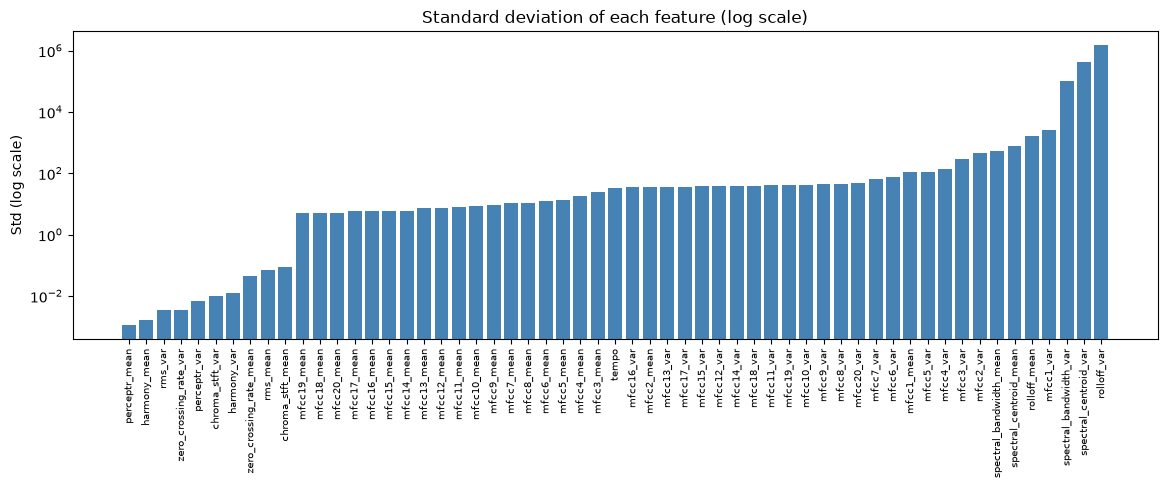

Smallest std: perceptr_mean 0.0011078224190243272
Largest std:  rolloff_var 1489398.2100910828


In [5]:
featureStd = dataSet[featureCols].std().sort_values()

plt.figure(figsize=(14, 4))
plt.bar(featureStd.index, featureStd.values, color="steelblue")
plt.yscale("log")
plt.title("Standard deviation of each feature (log scale)")
plt.ylabel("Std (log scale)")
plt.xticks(rotation=90, fontsize=7)
plt.show()

print("Smallest std:", featureStd.index[0], featureStd.values[0])
print("Largest std: ", featureStd.index[-1], featureStd.values[-1])

A legkisebb szórás a perceptr_mean (kb. 0,001), a legnagyobb a rolloff_var (kb. 1 500 000). A kettő között kb. 9 nagyságrend a különbség.
Skálázni kell (3.6), és a skálázás paramétereit csak a trainből lehet számolni. A fa alapú modellekre ez nem hat, a logisztikus regresszióra és a hálóra igen.

### 2.4 Eloszlások alakja

Négy hisztogram: egy átlag oszlop (chroma_stft_mean), egy variancia oszlop (mfcc11_var), ugyanennek a logaritmusa, és a tempo. Utána az összes jellemző ferdesége összesítve.
Azért kell, mert ferde eloszlásnál a logaritmus segíthet a lineáris modelleknek

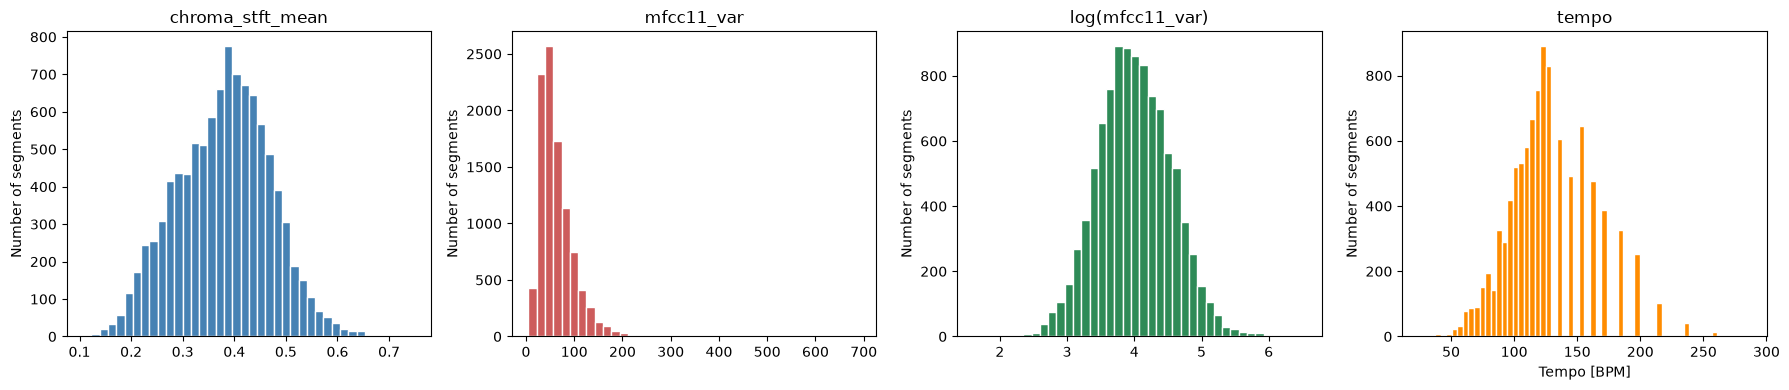

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

axes[0].hist(dataSet["chroma_stft_mean"], bins=40, color="steelblue", edgecolor="white")
axes[0].set_title("chroma_stft_mean")

axes[1].hist(dataSet["mfcc11_var"], bins=40, color="indianred", edgecolor="white")
axes[1].set_title("mfcc11_var")

axes[2].hist(np.log(dataSet["mfcc11_var"]), bins=40, color="seagreen", edgecolor="white")
axes[2].set_title("log(mfcc11_var)")

axes[3].hist(dataSet["tempo"], bins=60, color="darkorange", edgecolor="white")
axes[3].set_title("tempo")
axes[3].set_xlabel("Tempo [BPM]")

for ax in axes:
    ax.set_ylabel("Number of segments")

plt.tight_layout()
plt.show()

In [7]:
featureSkew = dataSet[featureCols].skew()

print("Features with skewness > 2:", (featureSkew > 2).sum(), "of", len(featureCols))
print("Average skewness of _var columns: ", round(featureSkew[varCols].mean(), 2))
print("Average skewness of _mean columns:", round(featureSkew[meanCols].mean(), 2))
print("Different tempo values:", dataSet["tempo"].nunique())

Features with skewness > 2: 22 of 57
Average skewness of _var columns:  2.76
Average skewness of _mean columns: -0.21
Different tempo values: 61


- A _mean oszlopok nagyjából szimmetrikusak, az átlagos ferdeségük -0,21.
- A _var oszlopok jobbra ferdék, az átlagos ferdeségük 2,76: a variancia nem lehet negatív, és néhány szeletnél nagyon nagy. Az 57 jellemzőből 22-nek 2 fölötti a ferdesége.
- Az mfcc11_var logaritmusa közel szimmetrikus.
- A tempo nem folytonos, csak 61 különböző értéket vesz fel.

### 2.5 Műfajok szétválása egy-egy jellemző mentén

Három jellemző eloszlása műfajonként boxploton: chroma_stft_mean, spectral_centroid_mean, tempo. A műfajok a medián szerint vannak sorba rendezve.
Azért kell, hogy kiderüljön, van-e olyan jellemző, ami önmagában szétválasztja a műfajokat, és olyan, ami szinte semmit nem mond róluk.

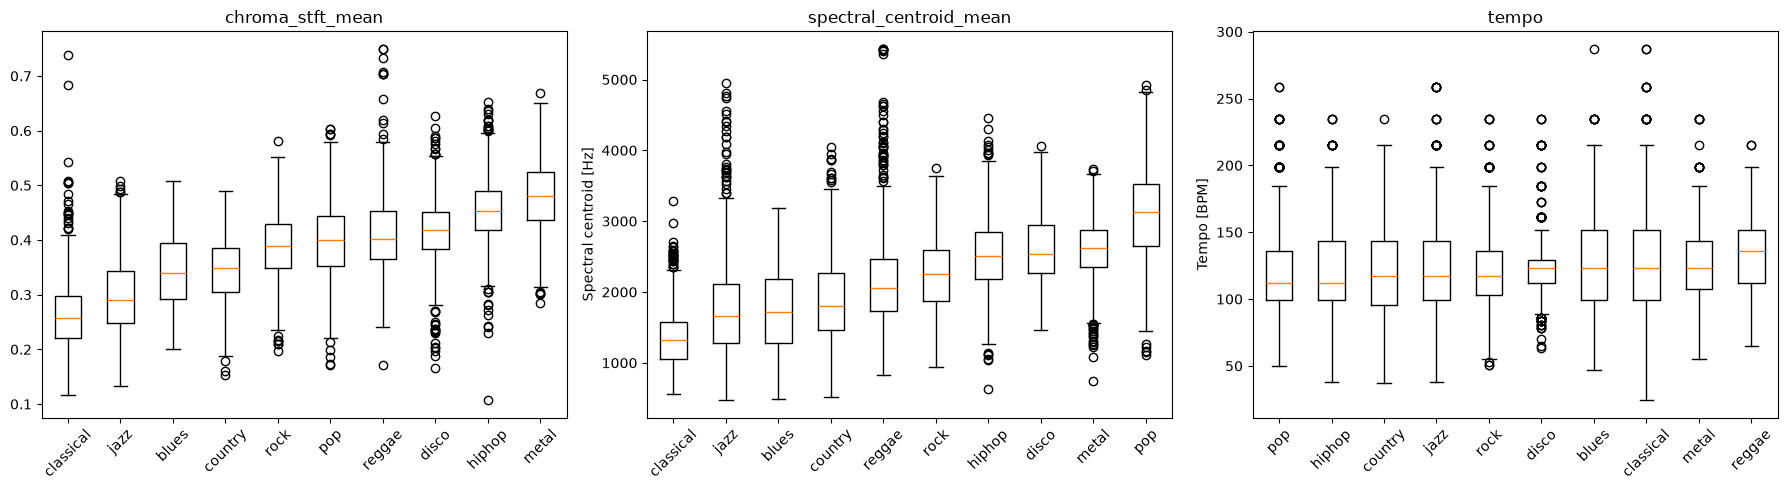

Median tempo per genre:
label
pop          112.3
hiphop       112.3
country      117.5
jazz         117.5
rock         117.5
disco        123.0
blues        123.0
classical    123.0
metal        123.0
reggae       136.0
Name: tempo, dtype: float64


In [8]:
boxFeatures = ["chroma_stft_mean", "spectral_centroid_mean", "tempo"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for index in range(len(boxFeatures)):
    feature = boxFeatures[index]
    ax = axes[index]

    genreOrder = dataSet.groupby("label")[feature].median().sort_values().index

    values = []
    for genre in genreOrder:
        values.append(dataSet.loc[dataSet["label"] == genre, feature])

    ax.boxplot(values)
    ax.set_xticks(range(1, len(genreOrder) + 1))
    ax.set_xticklabels(genreOrder, rotation=45)
    ax.set_title(feature)

axes[1].set_ylabel("Spectral centroid [Hz]")
axes[2].set_ylabel("Tempo [BPM]")
plt.tight_layout()
plt.show()

print("Median tempo per genre:")
print(dataSet.groupby("label")["tempo"].median().round(1).sort_values())

- chroma_stft_mean: a mediánok sorba rendeződnek, alul a classical (0,26), felül a metal (0,48). A középső műfajok (blues, country, rock, pop, reggae) dobozai átfednek.
- spectral_centroid_mean: alul a classical (kb. 1300 Hz), felül a pop (kb. 3100 Hz), a középső műfajok itt is átfednek.
- tempo: a mediánok 112 és 136 BPM között vannak, négy műfaj mediánja ugyanaz (123 BPM), a dobozok szinte teljesen átfednek. Ebből jön hogy a tempo önmagában alig mond valamit a műfajról.

### 2.6 Két jellemző együtt

Két jellemző pontdiagramon, műfajonként színezve: spectral_centroid_mean és rms_mean. Minden pont egy 3 mp-es szelet.
Azért kell, hogy kiderüljön, két erős jellemzővel szétválnak-e már a műfajok, vagy szükség van a többire is.

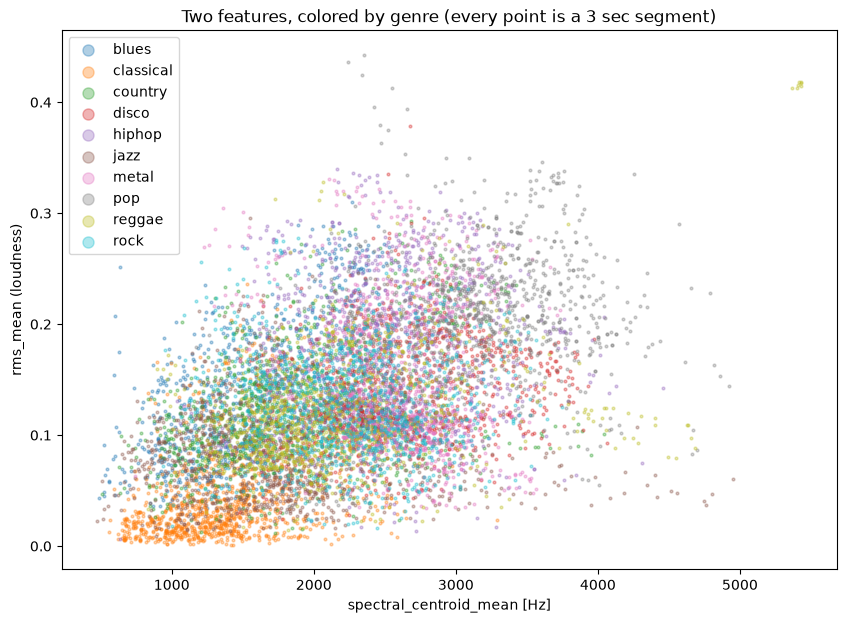

In [9]:
genreList = sorted(dataSet["label"].unique())

plt.figure(figsize=(10, 7))
for genre in genreList:
    genreRows = dataSet[dataSet["label"] == genre]
    plt.scatter(genreRows["spectral_centroid_mean"], genreRows["rms_mean"], s=4, alpha=0.35, label=genre)

plt.xlabel("spectral_centroid_mean [Hz]")
plt.ylabel("rms_mean (loudness)")
plt.title("Two features, colored by genre (every point is a 3 sec segment)")
plt.legend(markerscale=4)
plt.show()

A classical a bal alsó sarokban elkülönül (halk, alacsony centroid), a pop egy része jobbra fent van. A többi műfaj pontjai nagyrészt egymásra kerülnek.
Két jellemző nem elég, a modellnek a többi is kell. Ebből jön a 4. hipotézis: a classical lesz a legkönnyebben felismerhető műfaj, a középső műfajok egymással keverednek a legtöbbet.

## 3. Szűrés, előfeldolgozás

### 3.1 Duplikált értékek

Ha két szelet minden jellemzője megegyezik, akkor ugyanaz a hanganyag kétszer szerepel. Ilyenkor az extra zene minden szeletét eldobjuk. Ha nem dobnánk el akkor a modell a test-ben olyan hanganyagot kapna, amin már tanult.

In [10]:
duplicateRows = dataSet.duplicated(subset=featureCols, keep="first")
print("Duplicated segments:", duplicateRows.sum())

duplicateTracks = sorted(dataSet.loc[duplicateRows, "track"].unique())
print("Tracks removed:", len(duplicateTracks))
print(duplicateTracks)

dataSet = dataSet[~dataSet["track"].isin(duplicateTracks)]
dataSet = dataSet.reset_index(drop=True)

print("Shape after removing duplicate tracks:", dataSet.shape)
print("Duplicated segments left:", dataSet.duplicated(subset=featureCols).sum())

Duplicated segments: 143
Tracks removed: 15
['disco.00099', 'hiphop.00045', 'hiphop.00078', 'metal.00061', 'metal.00062', 'metal.00063', 'metal.00064', 'metal.00065', 'metal.00066', 'metal.00094', 'pop.00060', 'pop.00071', 'reggae.00074', 'reggae.00082', 'rock.00016']
Shape after removing duplicate tracks: (9840, 61)
Duplicated segments left: 0


15 zene esik ki, ebből 7 metal. A reggae.00074-nek csak néhány szelete egyezik a reggae.00073-mal, ezért a 30 mp-es táblában (egész zenére számolt jellemzők) ez nem látszana duplikátumnak.

### 3.2 Osztályeloszlás a szűrés után

Műfajonként megszámolja a zenéket a duplikátumok eldobása után. A max érték az eredeti 100 zene / műfaj.
Azért kell, mert ha az osztályok nem kiegyensúlyozottak, az accuracy félrevezető, és a vágásnál is figyelni kell rá.

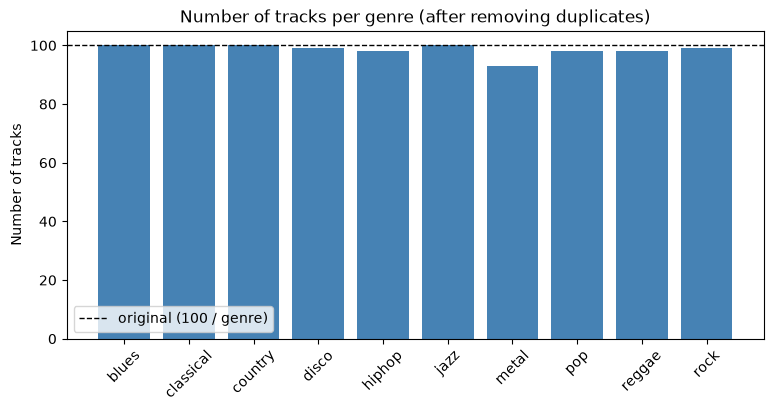

label
metal         93
hiphop        98
pop           98
reggae        98
rock          99
disco         99
country      100
classical    100
jazz         100
blues        100
Name: track, dtype: int64


In [11]:
classCounts = dataSet.groupby("label")["track"].nunique()

plt.figure(figsize=(9, 4))
plt.bar(classCounts.index, classCounts.values, color="steelblue")
plt.axhline(100, color="k", linestyle="--", linewidth=1, label="original (100 / genre)")
plt.title("Number of tracks per genre (after removing duplicates)")
plt.ylabel("Number of tracks")
plt.xticks(rotation=45)
plt.legend()
plt.show()

print(classCounts.sort_values())

Műfajonként 93 és 100 közötti zene maradt. Az osztályok kiegyensúlyozottak, az accuracy használható. A vágásnál stratify kell, hogy minden halmazban azonos arányban legyenek a műfajok.

### 3.3 Nem használt oszlopok, címkék, X és y

- filename: azonosító, és benne van a műfaj neve, a modell csalna vele
- length: a szelet hossza mintákban, nem a zenéről szól
- label: a célváltozó, számot kap (0–9)
- track: nem jellemző, csak a vágáshoz és a zene szintű kiértékeléshez kell, ezért külön változóba kerül

In [12]:
genreNames = {
    "blues": 0,
    "classical": 1,
    "country": 2,
    "disco": 3,
    "hiphop": 4,
    "jazz": 5,
    "metal": 6,
    "pop": 7,
    "reggae": 8,
    "rock": 9
}

dataSet = dataSet.drop(["filename", "length"], axis=1)
dataSet["label"] = dataSet["label"].map(genreNames)

X = dataSet[featureCols]
y = dataSet["label"]
track = dataSet["track"]

print("X:", X.shape)
print("y:", y.shape)
print("Missing labels after mapping:", y.isna().sum())

X: (9840, 57)
y: (9840,)
Missing labels after mapping: 0


### 3.4 Szeletek egy zenén belül

Öt zene szeletei két jellemző alapján, zenénként színezve.
Azért kell, hogy kiderüljön, mennyire hasonlítanak egymásra egy zene szeletei, és ebből mennyire kell figyelni a vágásnál.

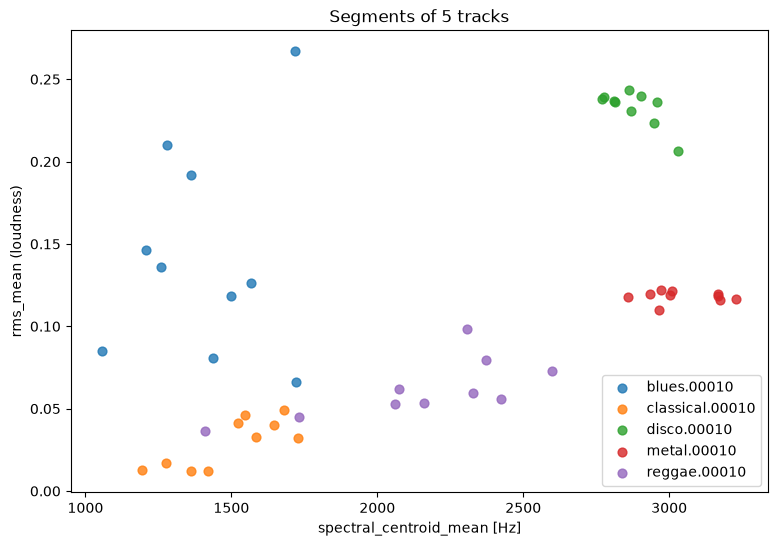

In [13]:
exampleTracks = ["blues.00010", "classical.00010", "disco.00010", "metal.00010", "reggae.00010"]

plt.figure(figsize=(9, 6))
for exampleTrack in exampleTracks:
    trackRows = dataSet[dataSet["track"] == exampleTrack]
    plt.scatter(trackRows["spectral_centroid_mean"], trackRows["rms_mean"], s=40, alpha=0.8, label=exampleTrack)

plt.xlabel("spectral_centroid_mean [Hz]")
plt.ylabel("rms_mean (loudness)")
plt.title("Segments of 5 tracks")
plt.legend()
plt.show()

Egy zene szeletei egymáshoz közel, külön csoportban vannak. Ha a vágás soronként történne, ugyanannak a zenének az egyik szelete a trainbe, egy másik a testbe kerülne, és a modell a testben egy már ismert zenét ismerne fel, nem a műfajt. Ezért a vágás zenénként történik.

### 3.5 Vágás zenénként: train / validation / test

Először a zenéket vágja 70 / 15 / 15 arányban, műfaj szerint stratify-jal (random_state=42), utána minden szelet abba a halmazba kerül, ahová a zenéje.

- train: ezen tanulnak a modellek
- validation: ezen választjuk ki a beállításokat és a modellt
- test: csak a legvégén, egyszer

In [14]:
trackLabels = dataSet.groupby("track")["label"].first()

tracksTrain, tracksTemp = train_test_split(trackLabels.index, test_size=0.3, stratify=trackLabels.values, random_state=42)
tracksVal, tracksTest = train_test_split(tracksTemp, test_size=0.5, stratify=trackLabels[tracksTemp].values, random_state=42)

trainMask = track.isin(tracksTrain)
valMask = track.isin(tracksVal)
testMask = track.isin(tracksTest)

X_train, y_train, track_train = X[trainMask], y[trainMask], track[trainMask]
X_val, y_val, track_val = X[valMask], y[valMask], track[valMask]
X_test, y_test, track_test = X[testMask], y[testMask], track[testMask]

print("Tracks   train:", len(tracksTrain), "val:", len(tracksVal), "test:", len(tracksTest))
print("Segments train:", X_train.shape[0], "val:", X_val.shape[0], "test:", X_test.shape[0])

Tracks   train: 689 val: 148 test: 148
Segments train: 6880 val: 1480 test: 1480


In [15]:
print("Tracks in both train and val: ", len(set(track_train) & set(track_val)))
print("Tracks in both train and test:", len(set(track_train) & set(track_test)))
print("Tracks in both val and test:  ", len(set(track_val) & set(track_test)))

distribution = pd.DataFrame({
    "train": trackLabels[tracksTrain].value_counts(normalize=True).sort_index(),
    "validation": trackLabels[tracksVal].value_counts(normalize=True).sort_index(),
    "test": trackLabels[tracksTest].value_counts(normalize=True).sort_index()
})
distribution.index = list(genreNames.keys())
(distribution * 100).round(1)

Tracks in both train and val:  0
Tracks in both train and test: 0
Tracks in both val and test:   0


,train,validation,test
blues,10.2,10.1,10.1
classical,10.2,10.1,10.1
country,10.2,10.1,10.1
disco,10.0,10.1,10.1
hiphop,10.0,9.5,10.1
jazz,10.2,10.1,10.1
metal,9.4,9.5,9.5
pop,10.0,10.1,9.5
reggae,9.9,10.1,10.1
rock,10.0,10.1,10.1


Egyik zene sem szerepel két halmazban, a műfajok aránya mindhárom halmazban kb. 10%.

### 3.6 Skálázás

StandardScaler a min-max helyett mert a _var oszlopok jobbra ferdék, és néhány nagyon nagy értékük (2.4) a min-max skálán a többi értéket 0 közelébe nyomná.
A fit csak a trainen fut, a transform mindhárom halmazon a train átlagával és szórásával.

In [16]:
scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = pd.DataFrame(scaler.transform(X_train), columns=featureCols, index=X_train.index)
X_val_scaled = pd.DataFrame(scaler.transform(X_val), columns=featureCols, index=X_val.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=featureCols, index=X_test.index)

check = pd.DataFrame({
    "train mean": X_train_scaled.mean(),
    "train std": X_train_scaled.std(),
    "test mean": X_test_scaled.mean(),
    "test std": X_test_scaled.std()
})
check.round(2).head(8)

,train mean,train std,test mean,test std
chroma_stft_mean,-0.0,1.0,0.00,1.01
chroma_stft_var,-0.0,1.0,-0.02,1.00
rms_mean,-0.0,1.0,0.02,0.99
rms_var,0.0,1.0,0.03,1.00
spectral_centroid_mean,-0.0,1.0,-0.02,1.05
spectral_centroid_var,0.0,1.0,0.06,1.03
spectral_bandwidth_mean,-0.0,1.0,0.03,1.08
spectral_bandwidth_var,-0.0,1.0,0.07,0.96


## 4. Jellemzők

A jellemzőket nem kell kinyerni, mert a táblákban már ki vannak számolva. Itt csak az van hogy melyik jellemző mennyi új információt hordoz, és kell-e rajtuk transzformáció.

### 4.1 Korreláció a jellemzők között

Az összes jellemző páronkénti Pearson korrelációja egy mátrixban, a train szeleteken. Utána a 10 legerősebb pár listája.
Azért kell, mert az erősen korreláló oszlopok ugyanazt az információt hordozzák. A korreláció csak lineáris összefüggést mér, és nem okság.

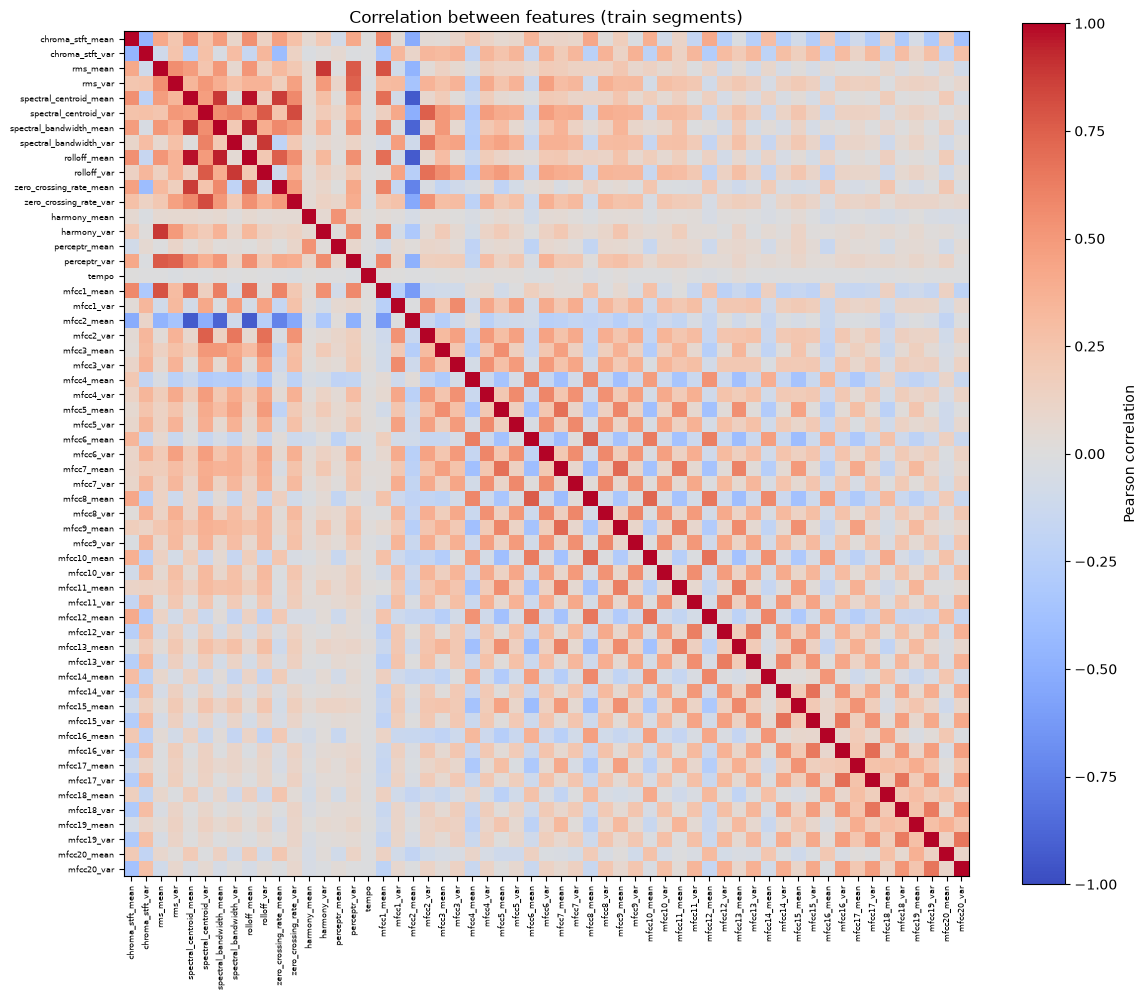

In [17]:
correlation = X_train[featureCols].corr()

plt.figure(figsize=(12, 10))
plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Pearson correlation")
plt.xticks(range(len(featureCols)), featureCols, rotation=90, fontsize=6)
plt.yticks(range(len(featureCols)), featureCols, fontsize=6)
plt.title("Correlation between features (train segments)")
plt.tight_layout()
plt.show()

In [18]:
pairs = []
for i in range(len(featureCols)):
    for j in range(i + 1, len(featureCols)):
        value = correlation.iloc[i, j]
        pairs.append((featureCols[i], featureCols[j], value))

pairs.sort(key=lambda pair: abs(pair[2]), reverse=True)

print("Top 10 correlated pairs:")
for pair in pairs[:10]:
    print(f"{pair[0]:28} {pair[1]:28} {pair[2]:.3f}")

Top 10 correlated pairs:
spectral_centroid_mean       rolloff_mean                 0.974
spectral_bandwidth_mean      rolloff_mean                 0.949
spectral_centroid_mean       mfcc2_mean                   -0.930
rolloff_mean                 mfcc2_mean                   -0.923
spectral_bandwidth_var       rolloff_var                  0.888
spectral_centroid_mean       spectral_bandwidth_mean      0.887
rms_mean                     harmony_var                  0.885
spectral_bandwidth_mean      mfcc2_mean                   -0.885
spectral_centroid_mean       zero_crossing_rate_mean      0.868
spectral_centroid_var        zero_crossing_rate_var       0.822


Négy spektrális jellemző (spectral_centroid_mean, rolloff_mean, spectral_bandwidth_mean, mfcc2_mean) egymással 0,89 és 0,97 közötti abszolút értékkel korrelál, az mfcc2_mean negatívan. A zero_crossing_rate_mean a spectral_centroid_mean-nel 0,87.
Ezek nagyrészt ugyanazt mérik. Ebből jön hogy közülük hármat elhagyva a pontosság nem romlik.

### 4.2 Log változat

A 2.4 diagram alapján a _var oszlopok jobbra ferdék. A log változatban a 28 _var oszlop helyére a logaritmusuk kerül, a többi oszlop változatlan. A legkisebb érték is pozitív, így a logaritmus mindenhol értelmezett.
A log változat külön skálázót kap, ugyanúgy csak a trainen illesztve.

In [19]:
print("Smallest value in the _var columns:", X[varCols].min().min())

X_log = X.copy()
for col in varCols:
    X_log[col] = np.log(X_log[col])

X_log_train = X_log[trainMask]
X_log_val = X_log[valMask]
X_log_test = X_log[testMask]

scalerLog = StandardScaler()
scalerLog.fit(X_log_train)

X_log_train_scaled = pd.DataFrame(scalerLog.transform(X_log_train), columns=featureCols, index=X_log_train.index)
X_log_val_scaled = pd.DataFrame(scalerLog.transform(X_log_val), columns=featureCols, index=X_log_val.index)
X_log_test_scaled = pd.DataFrame(scalerLog.transform(X_log_test), columns=featureCols, index=X_log_test.index)

logSkew = X_log[varCols].skew()
print("Average skewness of _var columns before log:", round(featureSkew[varCols].mean(), 2))
print("Average skewness of _var columns after log: ", round(logSkew.mean(), 2))

Smallest value in the _var columns: 9.312308610806998e-23
Average skewness of _var columns before log: 2.76
Average skewness of _var columns after log:  -0.41


A logaritmus után a _var oszlopok átlagos ferdesége 2,76-ról -0,41-re csökken. Hogy ez javít-e a modellen... az majd kiderűl

## Modellek

Minden modell a trainen tanul, a beállításait (pl. a fa mélysége) a validation zene szintű accuracy-je alapján választjuk ki. A test majd csak később jön

- baseline: mindig a leggyakoribb műfajt mondja
- logisztikus regresszió: lineáris modell, a skálázott adaton
- döntési fa, random forest, gradient boosting: fa alapú modellek, a skálázatlan adaton (rájuk a skálázás nem hat)

### 5.1 Kiértékelő függvények

- track_accuracy: egy zene szeleteire jósolt valószínűségeket átlagolja, és a legnagyobb valószínűségű műfajt adja a zenére
- evaluate: betanítja a modellt, és visszaadja a train és validation szelet szintű accuracy-t, a validation macro F1-et és a validation zene szintű accuracy-t
- best_of: egy eredménylistából a legjobb validation zene szintű accuracy-jű beállítást adja

In [20]:
def track_accuracy(model, X_part, y_part, track_part):
    probabilities = pd.DataFrame(model.predict_proba(X_part), index=X_part.index)
    probabilities["track"] = track_part.values

    trackProbabilities = probabilities.groupby("track").mean()
    trackPred = trackProbabilities.values.argmax(axis=1)

    trackTrue = y_part.groupby(track_part).first().loc[trackProbabilities.index]
    return accuracy_score(trackTrue, trackPred)


def evaluate(name, model, X_tr, X_va):
    model.fit(X_tr, y_train)
    trainPred = model.predict(X_tr)
    valPred = model.predict(X_va)

    result = {
        "model": name,
        "train accuracy": accuracy_score(y_train, trainPred),
        "val accuracy": accuracy_score(y_val, valPred),
        "val macro F1": f1_score(y_val, valPred, average="macro"),
        "val track accuracy": track_accuracy(model, X_va, y_val, track_val)
    }
    return result


def best_of(resultList):
    best = resultList[0]
    for result in resultList:
        if result["val track accuracy"] > best["val track accuracy"]:
            best = result
    return best

### 5.2 Baseline

Mindig a trainben leggyakoribb műfajt mondja. Ez az alsó határ ami ennél nem jobb, az nem tanult semmit. 10 közel egyforma osztálynál kb. 10% várható.

In [21]:
baselineResult = evaluate("baseline", DummyClassifier(strategy="most_frequent"), X_train, X_val)
pd.DataFrame([baselineResult]).round(3)

,model,train accuracy,val accuracy,val macro F1,val track accuracy
0,baseline,0.102,0.101,0.018,0.101


Accuracy 0,10

### 5.3 Logisztikus regresszió

A C a regularizáció erősségének fordítottja: kicsi C = erős büntetés a nagy súlyokra, nagy C = gyenge büntetés.
Az eredeti és a log változaton ugyanazokat a C értékeket próbáljuk ki, így látszik a logaritmus hatása.

In [22]:
cValues = [0.01, 0.1, 1, 10]

logRegResults = []
for c in cValues:
    result = evaluate("logreg C=" + str(c), LogisticRegression(C=c, max_iter=5000), X_train_scaled, X_val_scaled)
    result["data"] = "original"
    logRegResults.append(result)

    result = evaluate("logreg C=" + str(c), LogisticRegression(C=c, max_iter=5000), X_log_train_scaled, X_log_val_scaled)
    result["data"] = "log"
    logRegResults.append(result)

pd.DataFrame(logRegResults).round(3)

,model,train accuracy,val accuracy,val macro F1,val track accuracy,data
0,logreg C=0.01,0.711,0.659,0.659,0.736,original
1,logreg C=0.01,0.717,0.654,0.654,0.743,log
2,logreg C=0.1,0.740,0.676,0.677,0.770,original
3,logreg C=0.1,0.754,0.676,0.677,0.764,log
4,logreg C=1,0.751,0.686,0.687,0.777,original
5,logreg C=1,0.763,0.677,0.679,0.777,log
6,logreg C=10,0.754,0.681,0.683,0.777,original
7,logreg C=10,0.768,0.679,0.680,0.777,log


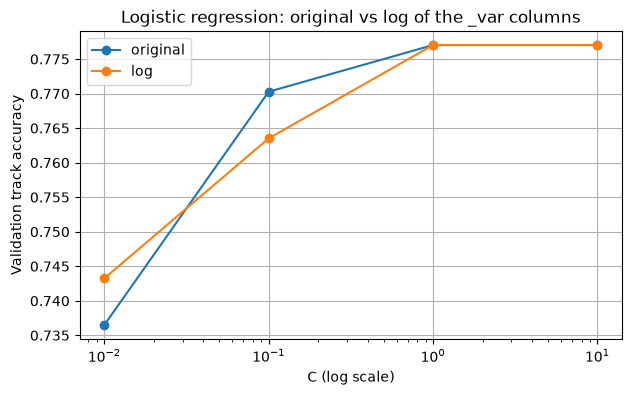

In [23]:
plt.figure(figsize=(7, 4))

for dataName in ["original", "log"]:
    accuracies = []
    for result in logRegResults:
        if result["data"] == dataName:
            accuracies.append(result["val track accuracy"])
    plt.plot(cValues, accuracies, marker="o", label=dataName)

plt.xscale("log")
plt.xlabel("C (log scale)")
plt.ylabel("Validation track accuracy")
plt.title("Logistic regression: original vs log of the _var columns")
plt.legend()
plt.grid()
plt.show()

Az eredeti adaton C=1-től a zene szintű accuracy 0,777-nél megáll. A train és a validation szelet szintű accuracy közti különbség kicsi (0,75 vs. 0,69), nincs erős túltanulás.
A log változat csak a legkisebb C-nél jobb (0,743 vs. 0,736), C=1-től ugyanannyi (0,777).

A logaritmus közelebb hozza a _var oszlopokat a normális eloszláshoz, de a logisztikus regresszió eredményén nem javítja.

### 5.4 Döntési fa

A jellemzők terét küszöbökkel régiókra osztja. A max_depth a fa mélysége: kis mélységnél alultanul, nagynál magolni kezd.

In [24]:
depthValues = [4, 8, 12, 16, None]

treeResults = []
for depth in depthValues:
    result = evaluate("tree depth=" + str(depth), DecisionTreeClassifier(max_depth=depth, random_state=42), X_train, X_val)
    treeResults.append(result)

pd.DataFrame(treeResults).round(3)

,model,train accuracy,val accuracy,val macro F1,val track accuracy
0,tree depth=4,0.400,0.368,0.310,0.405
1,tree depth=8,0.627,0.468,0.468,0.574
2,tree depth=12,0.849,0.493,0.497,0.642
3,tree depth=16,0.966,0.498,0.503,0.669
4,tree depth=None,1.000,0.500,0.505,0.689


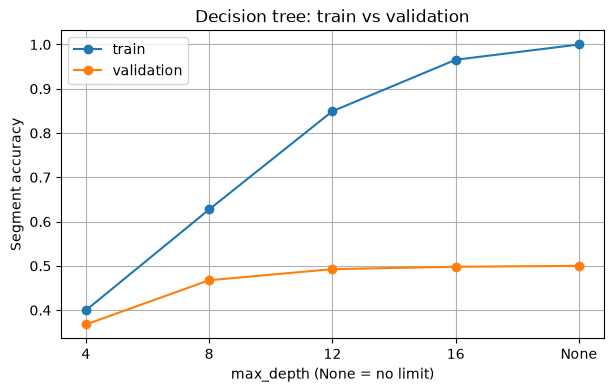

In [25]:
depthLabels = []
trainAccuracies = []
valAccuracies = []
for i in range(len(depthValues)):
    depthLabels.append(str(depthValues[i]))
    trainAccuracies.append(treeResults[i]["train accuracy"])
    valAccuracies.append(treeResults[i]["val accuracy"])

plt.figure(figsize=(7, 4))
plt.plot(depthLabels, trainAccuracies, marker="o", label="train")
plt.plot(depthLabels, valAccuracies, marker="o", label="validation")
plt.xlabel("max_depth (None = no limit)")
plt.ylabel("Segment accuracy")
plt.title("Decision tree: train vs validation")
plt.legend()
plt.grid()
plt.show()

A validation szelet szintű accuracy 12-es mélységtől 0,50 körül megáll, közben a train accuracy 1,0-ig nő, a mélyebb fa a train szeleteket magolja be. Zene szinten a legjobb 0,689 korlátlan mélység, ez jóval gyengébb a logisztikus regressziónál (az 0,777 volt).

A fa legfelső három szintje kirajzolva, hogy látszódjon, milyen jellemzők szerint dönt először.

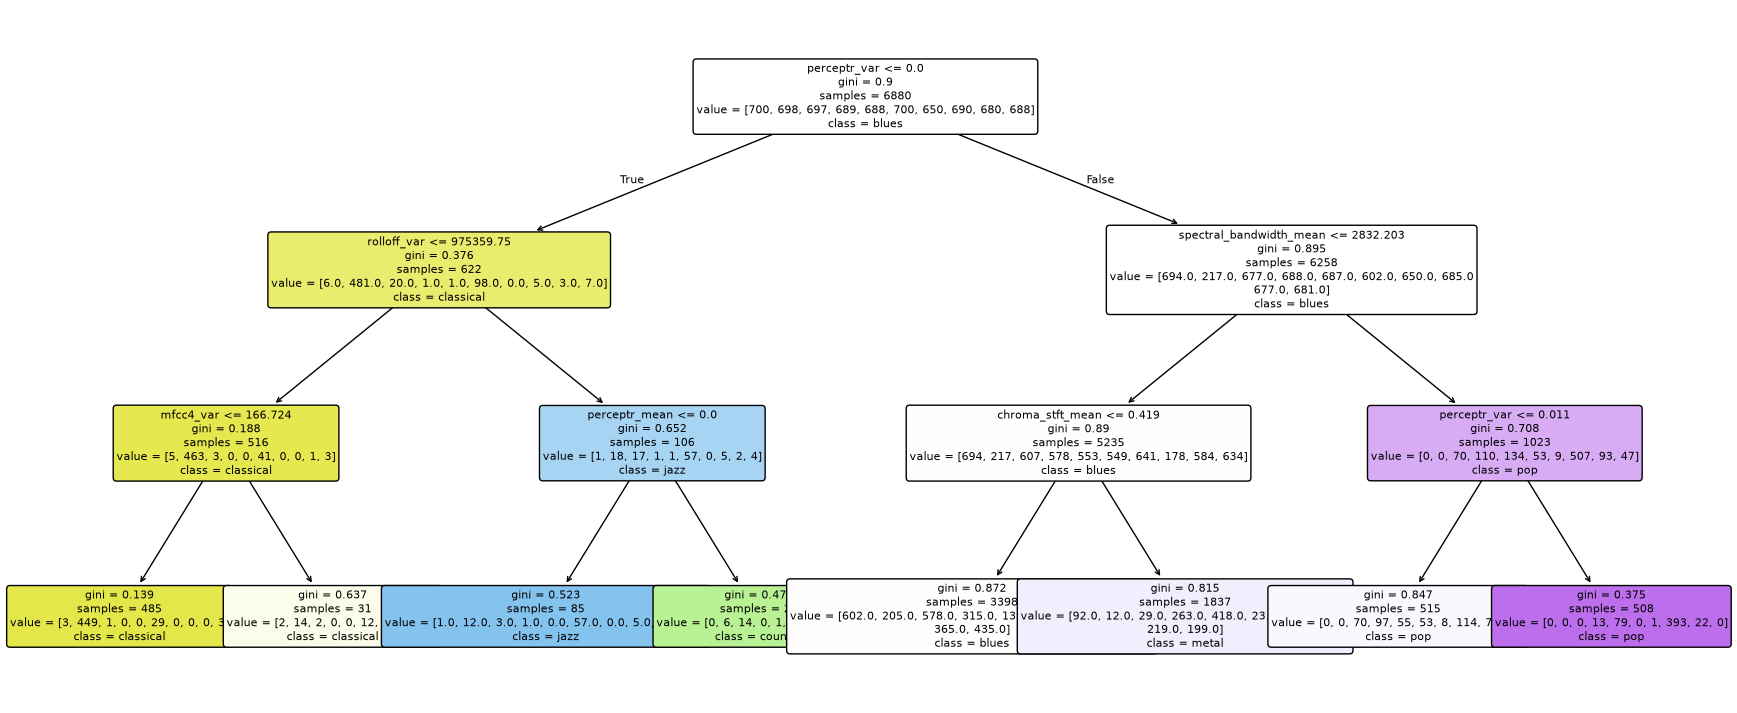

In [26]:
smallTree = DecisionTreeClassifier(max_depth=3, random_state=42)
smallTree.fit(X_train, y_train)

plt.figure(figsize=(22, 9))
plot_tree(smallTree, feature_names=featureCols, class_names=list(genreNames.keys()), filled=True, rounded=True, fontsize=8)
plt.show()

A gyökérben a perceptr_var alapján dönt: a nagyon kis értékű ágba szinte csak classical kerül (622 szeletből 481). A másik ágon a spectral_bandwidth_mean, utána a chroma_stft_mean és újra a perceptr_var dönt. Három szinttel csak 8 levél van, így a 10 műfajt nem is tudja mind szétválasztani.

### 5.5 Random forest

Sok döntési fa, mindegyik a train egy véletlen mintáján és a jellemzők egy véletlen részhalmazán tanul, a kimenet a fák szavazata.

In [27]:
treeCounts = [100, 300]

forestResults = []
for count in treeCounts:
    result = evaluate("forest trees=" + str(count), RandomForestClassifier(n_estimators=count, random_state=42, n_jobs=-1), X_train, X_val)
    forestResults.append(result)

pd.DataFrame(forestResults).round(3)

,model,train accuracy,val accuracy,val macro F1,val track accuracy
0,forest trees=100,1.0,0.693,0.694,0.730
1,forest trees=300,1.0,0.699,0.700,0.743


A train accuracy 1,0, mert a fák mélysége nincs korlátozva. Zene szinten 300 fával 0,743, ez jobb az egy fánál, de még mindig gyengébb a logisztikus regressziónál.

A random forest megadja a jellemzők fontosságát is hogy mennyit javítottak az adott jellemző szerinti döntések a fákban. Az ábra a 300 fás erdő jellemzőinek fontosságát mutatja, a tempo narancssárgával.

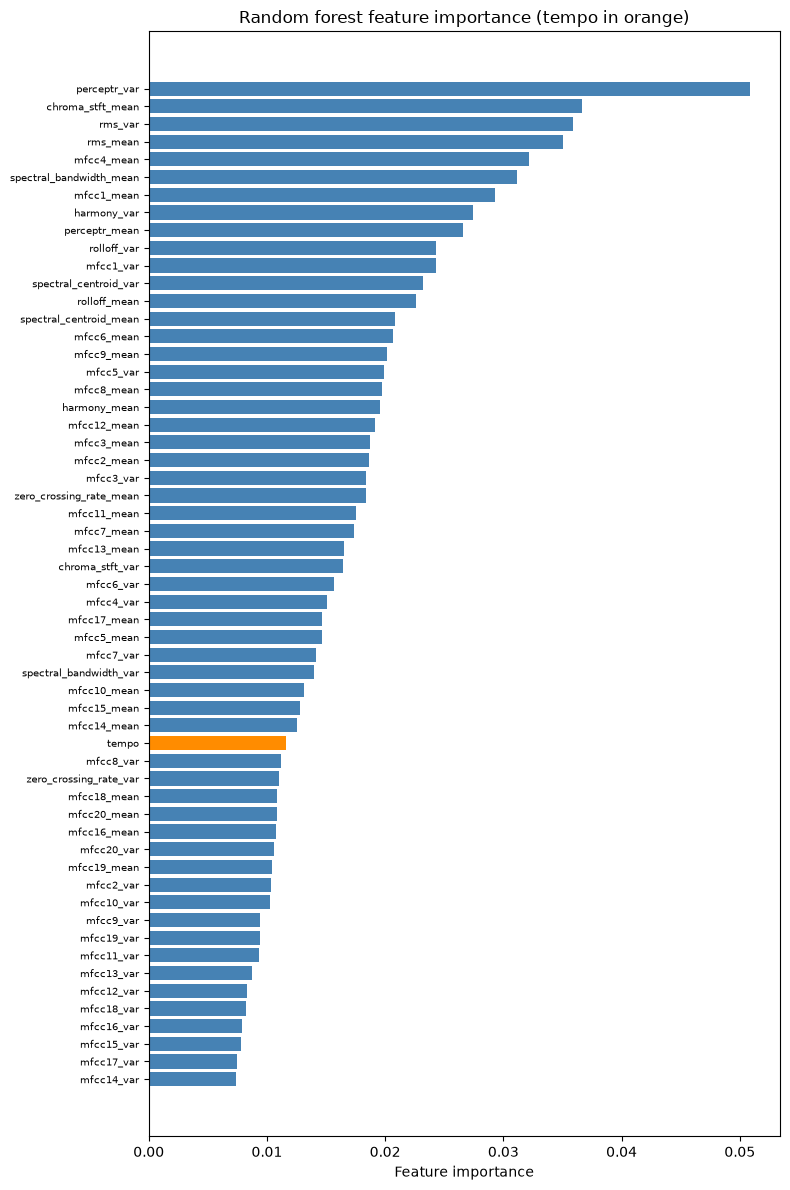

Tempo rank: 38 of 57
Top 5: ['perceptr_var', 'chroma_stft_mean', 'rms_var', 'rms_mean', 'mfcc4_mean']


In [28]:
forest = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
forest.fit(X_train, y_train)

importance = pd.Series(forest.feature_importances_, index=featureCols).sort_values()

colors = []
for name in importance.index:
    if name == "tempo":
        colors.append("darkorange")
    else:
        colors.append("steelblue")

plt.figure(figsize=(8, 12))
plt.barh(importance.index, importance.values, color=colors)
plt.xlabel("Feature importance")
plt.title("Random forest feature importance (tempo in orange)")
plt.yticks(fontsize=7)
plt.tight_layout()
plt.show()

ranking = list(importance.sort_values(ascending=False).index)
print("Tempo rank:", ranking.index("tempo") + 1, "of", len(ranking))
print("Top 5:", ranking[:5])

A legfontosabb jellemzők: perceptr_var, chroma_stft_mean, rms_var, rms_mean, mfcc4_mean. A tempo az 57 jellemzőből a 38. helyen van.

Mivel a tempo a jellemzők alsó felében van, a műfajt önmagában kevéssé határozza meg, de nem a legkevésbé fontos jellemző.

### 5.6 Gradient boosting

Szintén fák, de egymás után tanulnak: minden új fa az előzőek hibáját próbálja javítani. A learning_rate azt adja meg, mekkora súllyal kerül be egy új fa.
A HistGradientBoostingClassifier a jellemzőket sávokba sorolja, ezért kb. 7000 sornál sokkal gyorsabb, mint a GradientBoostingClassifier.

In [29]:
learningRates = [0.05, 0.1]

boostResults = []
for rate in learningRates:
    result = evaluate("boosting lr=" + str(rate), HistGradientBoostingClassifier(learning_rate=rate, max_iter=300, random_state=42), X_train, X_val)
    boostResults.append(result)

pd.DataFrame(boostResults).round(3)

,model,train accuracy,val accuracy,val macro F1,val track accuracy
0,boosting lr=0.05,1.0,0.729,0.731,0.784
1,boosting lr=0.1,1.0,0.731,0.732,0.791


Zene szinten 0,784 (learning_rate=0,05) és 0,791 (learning_rate=0,1). Szelet szinten is ez a legjobb modell (0,731). A train accuracy itt is 1,0.

### 5.7 Korreláló jellemzők elhagyása

A spectral_centroid_mean, rolloff_mean, spectral_bandwidth_mean és mfcc2_mean nagyrészt ugyanazt méri. Csak a spectral_centroid_mean marad, a másik hármat elhagyjuk, és ugyanazokkal a beállításokkal újratanítjuk a logisztikus regressziót és a random forestet.

In [30]:
droppedCols = ["rolloff_mean", "spectral_bandwidth_mean", "mfcc2_mean"]
bestLogRegC = float(best_of(logRegResults)["model"].split("=")[1])

reducedResults = []

result = evaluate("logreg full", LogisticRegression(C=bestLogRegC, max_iter=5000), X_train_scaled, X_val_scaled)
reducedResults.append(result)

result = evaluate("logreg reduced", LogisticRegression(C=bestLogRegC, max_iter=5000), X_train_scaled.drop(droppedCols, axis=1), X_val_scaled.drop(droppedCols, axis=1))
reducedResults.append(result)

result = evaluate("forest full", RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1), X_train, X_val)
reducedResults.append(result)

result = evaluate("forest reduced", RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1), X_train.drop(droppedCols, axis=1), X_val.drop(droppedCols, axis=1))
reducedResults.append(result)

pd.DataFrame(reducedResults).round(3)

,model,train accuracy,val accuracy,val macro F1,val track accuracy
0,logreg full,0.751,0.686,0.687,0.777
1,logreg reduced,0.748,0.683,0.684,0.777
2,forest full,1.000,0.699,0.700,0.743
3,forest reduced,1.000,0.720,0.722,0.770


A logisztikus regresszió zene szinten ugyanannyi (0,777), a random forest 0,743-ról 0,770-re javult. A javulás 4 zene a 148-ból, ami ekkora validation halmazon akár még a zaj határán van.

De, a három oszlop elhagyása nem ront.

### 5.8 Modellek összehasonlítása

In [31]:
bestLogReg = best_of(logRegResults)
bestTree = best_of(treeResults)
bestForest = best_of(forestResults)
bestBoost = best_of(boostResults)

summary = [baselineResult, bestLogReg, bestTree, bestForest, bestBoost]
summaryTable = pd.DataFrame(summary)[["model", "train accuracy", "val accuracy", "val macro F1", "val track accuracy"]]
summaryTable.round(3)

,model,train accuracy,val accuracy,val macro F1,val track accuracy
0,baseline,0.102,0.101,0.018,0.101
1,logreg C=1,0.751,0.686,0.687,0.777
2,tree depth=None,1.000,0.500,0.505,0.689
3,forest trees=300,1.000,0.699,0.700,0.743
4,boosting lr=0.1,1.000,0.731,0.732,0.791


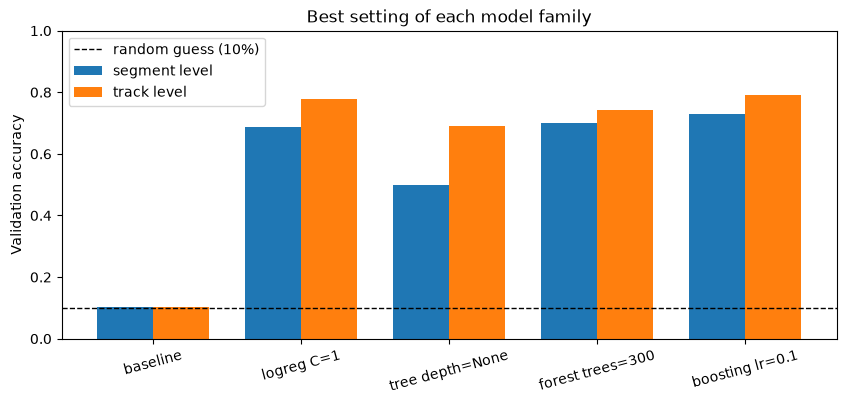

In [32]:
positions = np.arange(len(summaryTable))
width = 0.38

plt.figure(figsize=(10, 4))
plt.bar(positions - width / 2, summaryTable["val accuracy"], width, label="segment level")
plt.bar(positions + width / 2, summaryTable["val track accuracy"], width, label="track level")
plt.axhline(0.1, color="k", linestyle="--", linewidth=1, label="random guess (10%)")
plt.xticks(positions, summaryTable["model"], rotation=15)
plt.ylabel("Validation accuracy")
plt.ylim(0, 1)
plt.title("Best setting of each model family")
plt.legend()
plt.show()

- Minden modell jóval a baseline (0,10) fölött van.
- Zene szinten a sorrend: gradient boosting (0,791), logisztikus regresszió (0,777), random forest (0,743), döntési fa (0,689).
- A zene szintű accuracy minden modellnél magasabb a szelet szintűnél, egy-egy szeletet a modell eltéveszthet, de a szeletek átlaga a jó műfaj felé húz.
- A fa alapú modellek train accuracy-je 1,0, a logisztikus regresszióé 0,75.

A gradient boosting és a logisztikus regresszió közti különbség 2 zene a 148-ból, ez ekkora validation halmazon nem megbízható különbség. A logisztikus regresszió egyszerűbb, gyorsabb és nem tanul túl

## 6. Kiértékelés, összehasonlítás

### 6.1 A teszt

A kiválasztott modell egyszer fut a teszten. A teszt eredménye azt becsli, hogyan teljesít a modell olyan zenéken, amiket sem tanuláskor, sem a beállítások kiválasztásakor nem látott.

In [33]:
finalModel = LogisticRegression(C=bestLogRegC, max_iter=5000)
finalModel.fit(X_train_scaled, y_train)

segmentTestPred = finalModel.predict(X_test_scaled)
print("Best C:", bestLogRegC)
print("Test segment accuracy:", round(accuracy_score(y_test, segmentTestPred), 3))
print("Test track accuracy:  ", round(track_accuracy(finalModel, X_test_scaled, y_test, track_test), 3))

Best C: 1.0
Test segment accuracy: 0.661
Test track accuracy:   0.784


Szelet szinten 0,661, zene szinten 0,784. A teszt zene szintű eredménye közel van a validation-höz (0,777).

A confusion matrix a test zenéken, zene szinten: a sorok a valós műfajok, az oszlopok a jósoltak. Az átló a jól eltalált zenék száma, az átlón kívüli cellák mutatják, melyik műfajt mivel keveri a modell. Alatta a műfajonkénti precision, recall és F1.

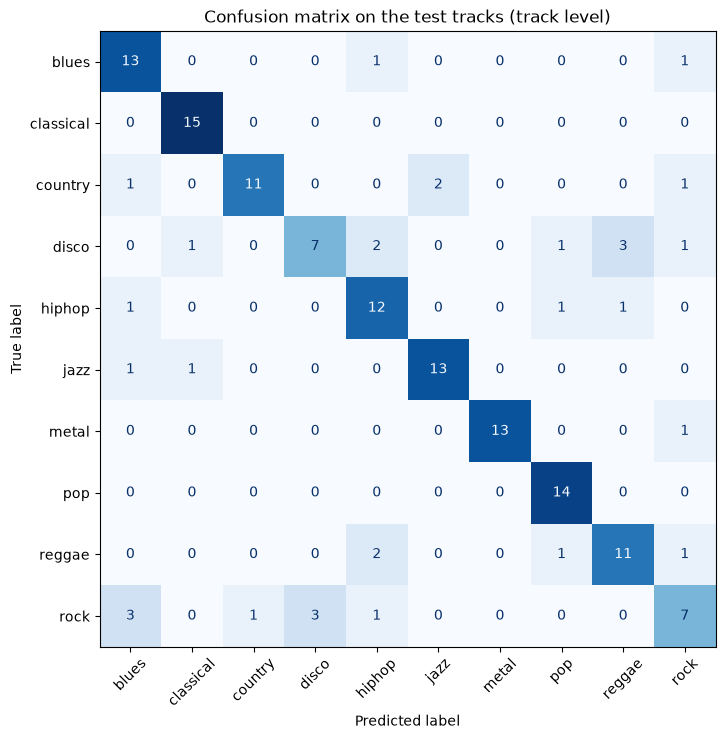

              precision    recall  f1-score   support

       blues       0.68      0.87      0.76        15
   classical       0.88      1.00      0.94        15
     country       0.92      0.73      0.81        15
       disco       0.70      0.47      0.56        15
      hiphop       0.67      0.80      0.73        15
        jazz       0.87      0.87      0.87        15
       metal       1.00      0.93      0.96        14
         pop       0.82      1.00      0.90        14
      reggae       0.73      0.73      0.73        15
        rock       0.58      0.47      0.52        15

    accuracy                           0.78       148
   macro avg       0.79      0.79      0.78       148
weighted avg       0.78      0.78      0.78       148



In [34]:
testProbabilities = pd.DataFrame(finalModel.predict_proba(X_test_scaled), index=X_test_scaled.index)
testProbabilities["track"] = track_test.values
trackProbabilities = testProbabilities.groupby("track").mean()

trackTestPred = trackProbabilities.values.argmax(axis=1)
trackTestTrue = y_test.groupby(track_test).first().loc[trackProbabilities.index]

cm = confusion_matrix(trackTestTrue, trackTestPred)

fig, ax = plt.subplots(figsize=(9, 8))
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=list(genreNames.keys()))
display.plot(ax=ax, cmap="Blues", colorbar=False)
plt.xticks(rotation=45)
plt.title("Confusion matrix on the test tracks (track level)")
plt.show()

print(classification_report(trackTestTrue, trackTestPred, target_names=list(genreNames.keys())))

- Legjobb: metal (F1 0,96), classical (0,94), pop (0,90). A classical mind a 15 zenéjét eltalálta.
- Leggyengébb: rock (0,52), disco (0,56). A rockot leggyakrabban bluesnak (3) és discónak (3) nézi, a discót reggae-nek (3) és hiphopnak (2).

A classical a legkönnyebben felismerhető műfajok között van (recall 1,0), és a gyenge műfajok a középső tartományból jönnek. A metal és a pop viszont ugyanolyan jól elkülönül, mint a classical. Ez részben látható volt a pont diagrammon

### 6.2 30 mp-es és 3 mp-es tábla

A 30 mp-es táblán ugyanazok a zenék ugyanazokba a halmazokba kerülnek, mint a 3 mp-es táblán, így a két tábla ugyanazokon a zenéken hasonlítható össze. A 30 mp-es táblán is a validation alapján választjuk a C-t.
Két modell fut mindkét táblán: a logisztikus regresszió és egy kis neurális háló (MLPClassifier, 1 rejtett réteg 64 neuronnal, early stopping)

In [35]:
dataSet30 = pd.read_csv("data/features_30_sec.csv")

trackIds30 = []
for filename in dataSet30["filename"]:
    parts = filename.split(".")
    trackIds30.append(parts[0] + "." + parts[1])
dataSet30["track"] = trackIds30

# same tracks in the same sets as in the 3 sec table
dataSet30 = dataSet30[dataSet30["track"].isin(trackLabels.index)]
dataSet30["label"] = dataSet30["label"].map(genreNames)

train30 = dataSet30[dataSet30["track"].isin(tracksTrain)]
val30 = dataSet30[dataSet30["track"].isin(tracksVal)]
test30 = dataSet30[dataSet30["track"].isin(tracksTest)]

scaler30 = StandardScaler()
scaler30.fit(train30[featureCols])

X30_train = scaler30.transform(train30[featureCols])
X30_val = scaler30.transform(val30[featureCols])
X30_test = scaler30.transform(test30[featureCols])

print("30 sec tracks  train:", len(train30), "val:", len(val30), "test:", len(test30))

30 sec tracks  train: 689 val: 148 test: 148


In [36]:
# 30 sec table: C chosen on the validation set, the same way as for the 3 sec table
best30C = cValues[0]
best30Accuracy = 0
for c in cValues:
    model = LogisticRegression(C=c, max_iter=5000)
    model.fit(X30_train, train30["label"])
    accuracy = accuracy_score(val30["label"], model.predict(X30_val))
    if accuracy > best30Accuracy:
        best30Accuracy = accuracy
        best30C = c

logReg30 = LogisticRegression(C=best30C, max_iter=5000)
logReg30.fit(X30_train, train30["label"])

mlp30 = MLPClassifier(hidden_layer_sizes=(64,), max_iter=500, early_stopping=True, random_state=42)
mlp30.fit(X30_train, train30["label"])

mlp3 = MLPClassifier(hidden_layer_sizes=(64,), max_iter=500, early_stopping=True, random_state=42)
mlp3.fit(X_train_scaled, y_train)

comparison = pd.DataFrame({
    "30 sec val": [
        accuracy_score(val30["label"], logReg30.predict(X30_val)),
        accuracy_score(val30["label"], mlp30.predict(X30_val))
    ],
    "3 sec val (track level)": [
        track_accuracy(finalModel, X_val_scaled, y_val, track_val),
        track_accuracy(mlp3, X_val_scaled, y_val, track_val)
    ],
    "30 sec test": [
        accuracy_score(test30["label"], logReg30.predict(X30_test)),
        accuracy_score(test30["label"], mlp30.predict(X30_test))
    ],
    "3 sec test (track level)": [
        track_accuracy(finalModel, X_test_scaled, y_test, track_test),
        track_accuracy(mlp3, X_test_scaled, y_test, track_test)
    ]
}, index=["logistic regression", "MLP (64)"])

print("Best C on the 30 sec table:", best30C)
comparison.round(3)

Best C on the 30 sec table: 1


,30 sec val,3 sec val (track level),30 sec test,3 sec test (track level)
logistic regression,0.770,0.777,0.730,0.784
MLP (64),0.635,0.804,0.649,0.770


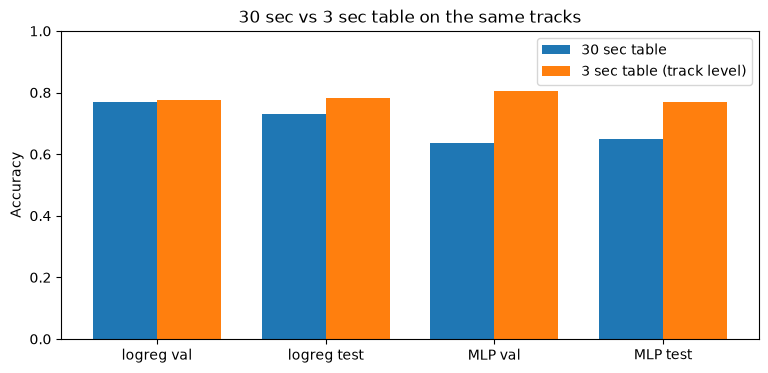

In [37]:
positions = np.arange(4)
width = 0.38
labels = ["logreg val", "logreg test", "MLP val", "MLP test"]

values30 = [comparison.loc["logistic regression", "30 sec val"], comparison.loc["logistic regression", "30 sec test"],
            comparison.loc["MLP (64)", "30 sec val"], comparison.loc["MLP (64)", "30 sec test"]]
values3 = [comparison.loc["logistic regression", "3 sec val (track level)"], comparison.loc["logistic regression", "3 sec test (track level)"],
           comparison.loc["MLP (64)", "3 sec val (track level)"], comparison.loc["MLP (64)", "3 sec test (track level)"]]

plt.figure(figsize=(9, 4))
plt.bar(positions - width / 2, values30, width, label="30 sec table")
plt.bar(positions + width / 2, values3, width, label="3 sec table (track level)")
plt.xticks(positions, labels)
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.title("30 sec vs 3 sec table on the same tracks")
plt.legend()
plt.show()

- Logisztikus regresszió: validation-ön 0,770 vs. 0,777, teszten 0,730 vs. 0,784.
- Kis háló: validation-ön 0,635 vs. 0,804, teszten 0,649 vs. 0,770.

Mind a négy összehasonlításban a 3 mp-es tábla jobb. A logisztikus regressziónál a validation-ön a különbség csak 1 zene, a hálónál viszont nagy: a 30 mp-es táblán 689 tanító sor kevés a háló súlyainak, a 3 mp-es táblán 6880 sor van.

### Összegzés

- A legjobb modell a validation-ön a gradient boosting (0,791) és a logisztikus regresszió (0,777) volt, a kettő közti különbség a zaj határán van. A végső modell a logisztikus regresszió, a teszten zene szinten 0,784, szemben a véletlen tipp 0,10-ával.
- A legfontosabb előfeldolgozási rész a zenénkénti vágás és a duplikált zenék eldobása volt. Nélkülük ugyanannak a zenének a szeletei több halmazba kerülnének, és a teszt eredmény a valósnál jobb lenne.
- A rock és a disco felismerése a leggyengébb: ezeknél a jellemzők átfednek a szomszédos műfajokkal.

## 7. Eredmény Export

In [38]:
outputDir = "output"
os.makedirs(outputDir, exist_ok=True)

trainExport = X_train_scaled.copy()
trainExport["label"] = y_train
trainExport["track"] = track_train

valExport = X_val_scaled.copy()
valExport["label"] = y_val
valExport["track"] = track_val

testExport = X_test_scaled.copy()
testExport["label"] = y_test
testExport["track"] = track_test

trainExport.to_csv(os.path.join(outputDir, "train.csv"), index=False)
valExport.to_csv(os.path.join(outputDir, "val.csv"), index=False)
testExport.to_csv(os.path.join(outputDir, "test.csv"), index=False)

print("train.csv:", trainExport.shape)
print("val.csv:  ", valExport.shape)
print("test.csv: ", testExport.shape)

train.csv: (6880, 59)
val.csv:   (1480, 59)
test.csv:  (1480, 59)


In [39]:
scaleParamsExport = {
    "featureOrder": featureCols,
    "mean": {},
    "std": {}
}

for i in range(len(featureCols)):
    col = featureCols[i]
    scaleParamsExport["mean"][col] = float(scaler.mean_[i])
    scaleParamsExport["std"][col] = float(scaler.scale_[i])

with open(os.path.join(outputDir, "scale_params.json"), "w") as file:
    json.dump(scaleParamsExport, file, indent=2)

genresExport = {}
for name, index in genreNames.items():
    genresExport[index] = name

with open(os.path.join(outputDir, "genres.json"), "w") as file:
    json.dump(genresExport, file, indent=2)

print("Saved files:", sorted(os.listdir(outputDir)))

Saved files: ['genres.json', 'scale_params.json', 'test.csv', 'train.csv', 'val.csv']
